# PENSE 2024 — MCA: análise ampliada — versão V3

Notebook para autovalores, Scree Plot, inércia por dimensão e acumulada (bruta e corrigida), contribuições, Cos², mapas fatoriais e preparação das coordenadas para K-means.

**Antes de executar:** confira o caminho do arquivo de entrada na seção 1 e verifique a versão da biblioteca `prince`.

Dimensões originais: (118036, 39)

Tipos de dados:
category    25
category     9
category     1
category     1
category     1
category     1
category     1
Name: count, dtype: int64

Percentual de valores ausentes por variável:
CAPITAL - indica se é município da capital                                                                                                                                                                                                                 0.0
B01001A - Qual é o seu sexo?                                                                                                                                                                                                                               0.0
IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS                                                                                                                                                                                                               0.0
B01002 

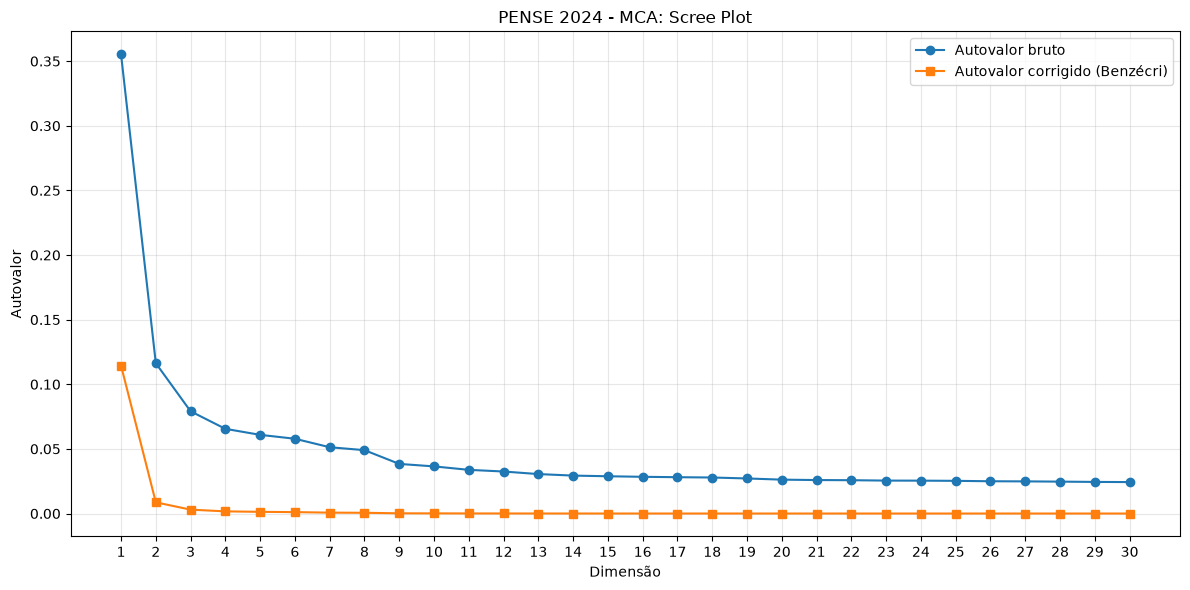

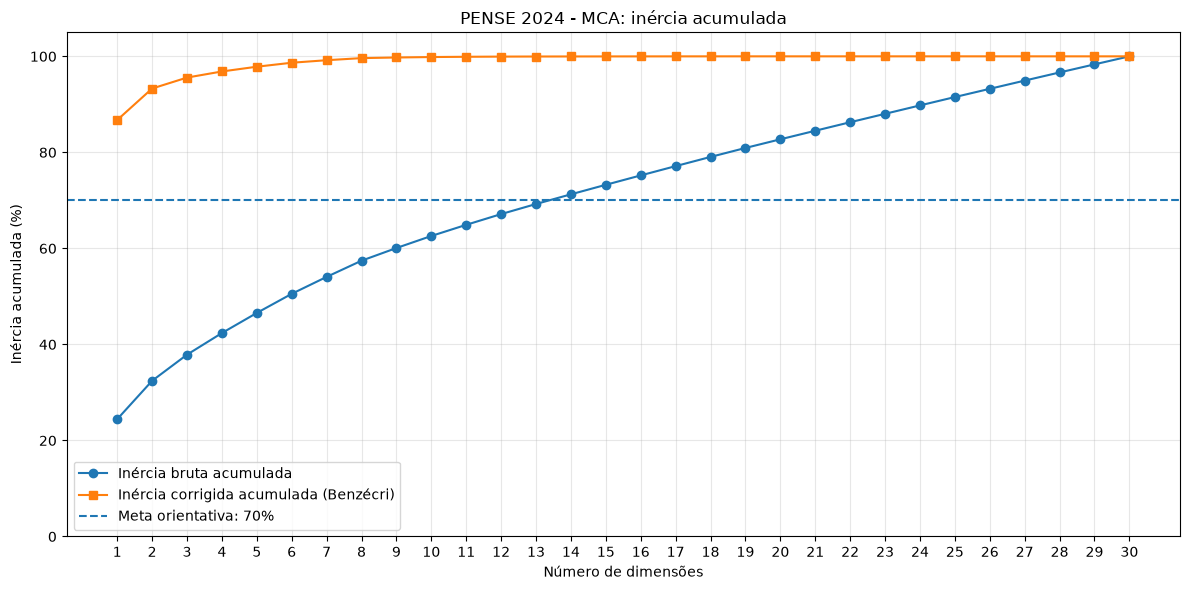


========== CONTRIBUIÇÃO DAS CATEGORIAS ==========
Soma das contribuições por dimensão (%):
MCA_1     100.0
MCA_2     100.0
MCA_3     100.0
MCA_4     100.0
MCA_5     100.0
MCA_6     100.0
MCA_7     100.0
MCA_8     100.0
MCA_9     100.0
MCA_10    100.0
MCA_11    100.0
MCA_12    100.0
MCA_13    100.0
MCA_14    100.0
MCA_15    100.0
MCA_16    100.0
MCA_17    100.0
MCA_18    100.0
MCA_19    100.0
MCA_20    100.0
MCA_21    100.0
MCA_22    100.0
MCA_23    100.0
MCA_24    100.0
MCA_25    100.0
MCA_26    100.0
MCA_27    100.0
MCA_28    100.0
MCA_29    100.0
MCA_30    100.0

MCA_1 - 20 categorias com maior contribuição
B12005 - NOS ÚLTIMOS 30 DIAS, com que frequência você se sentiu triste?__0                                                                                                                                         4.755
B07013 - NOS ÚLTIMOS 30 DIAS, você se sentiu ameaçado(a), ofendido(a) ou humilhado(a) nas redes sociais ou aplicativos de celular?__0                                

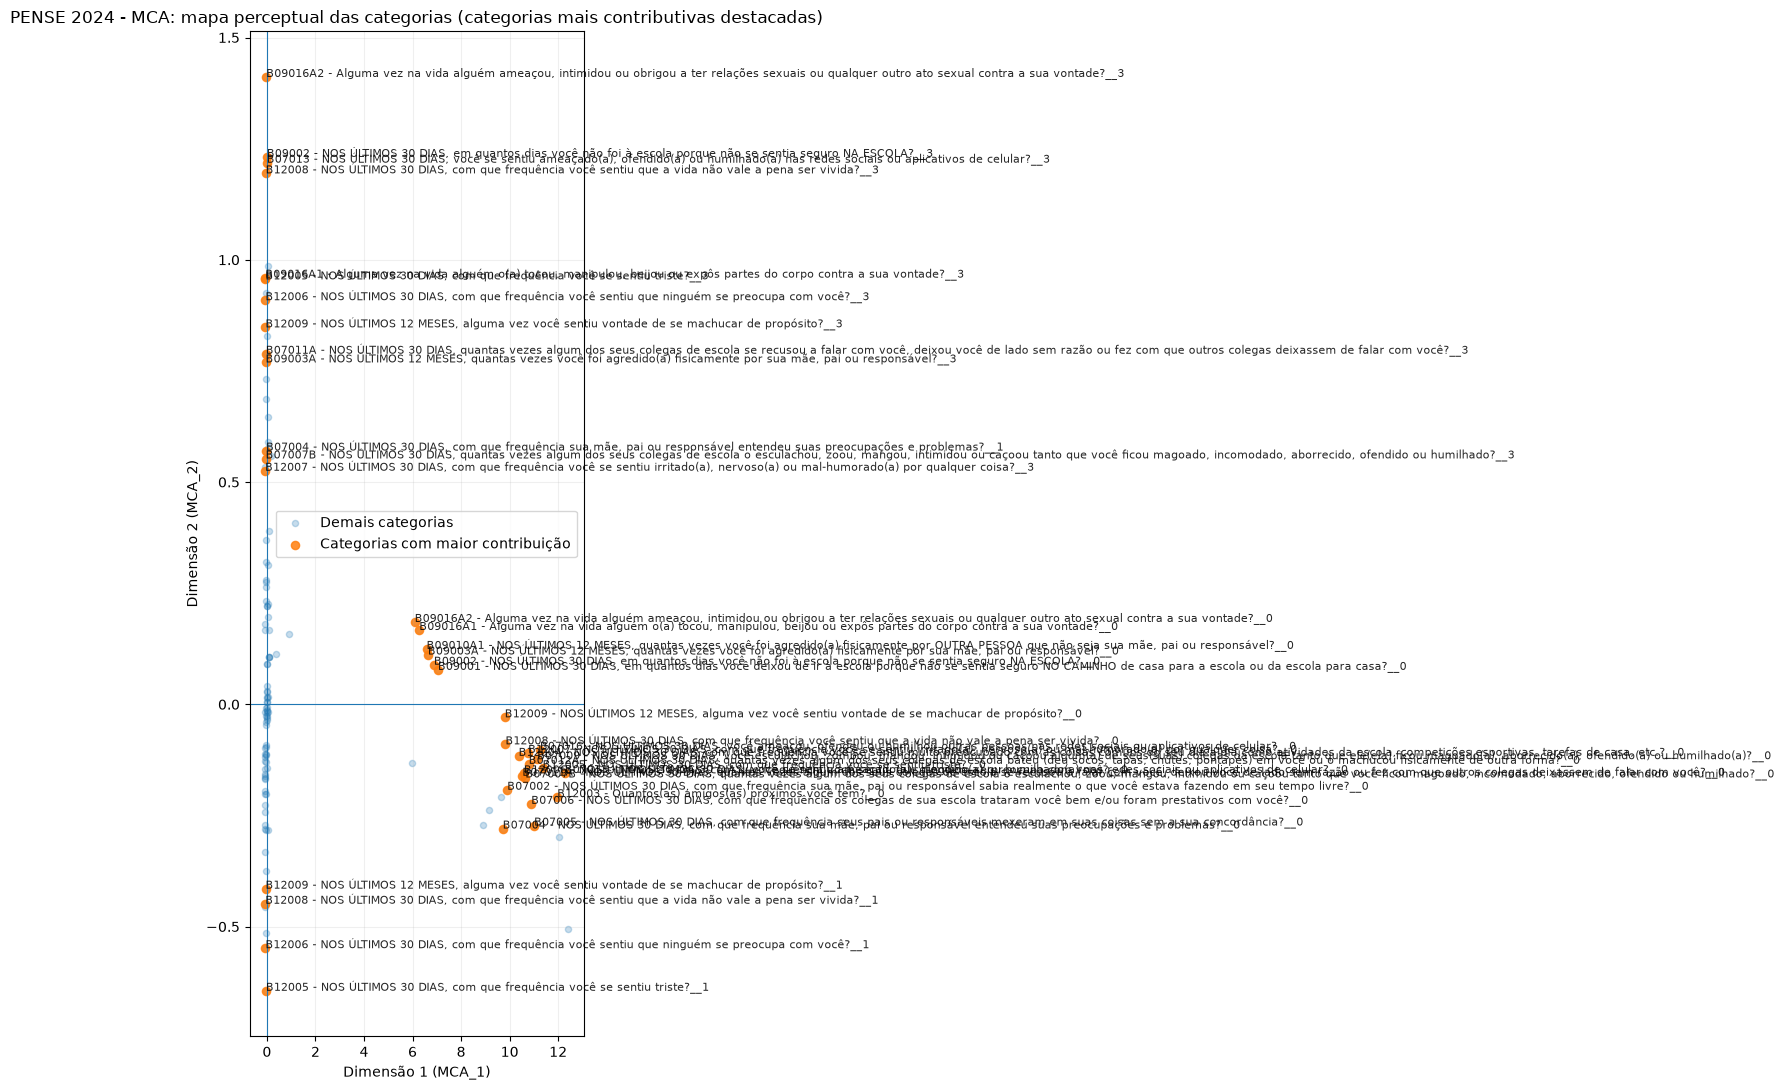

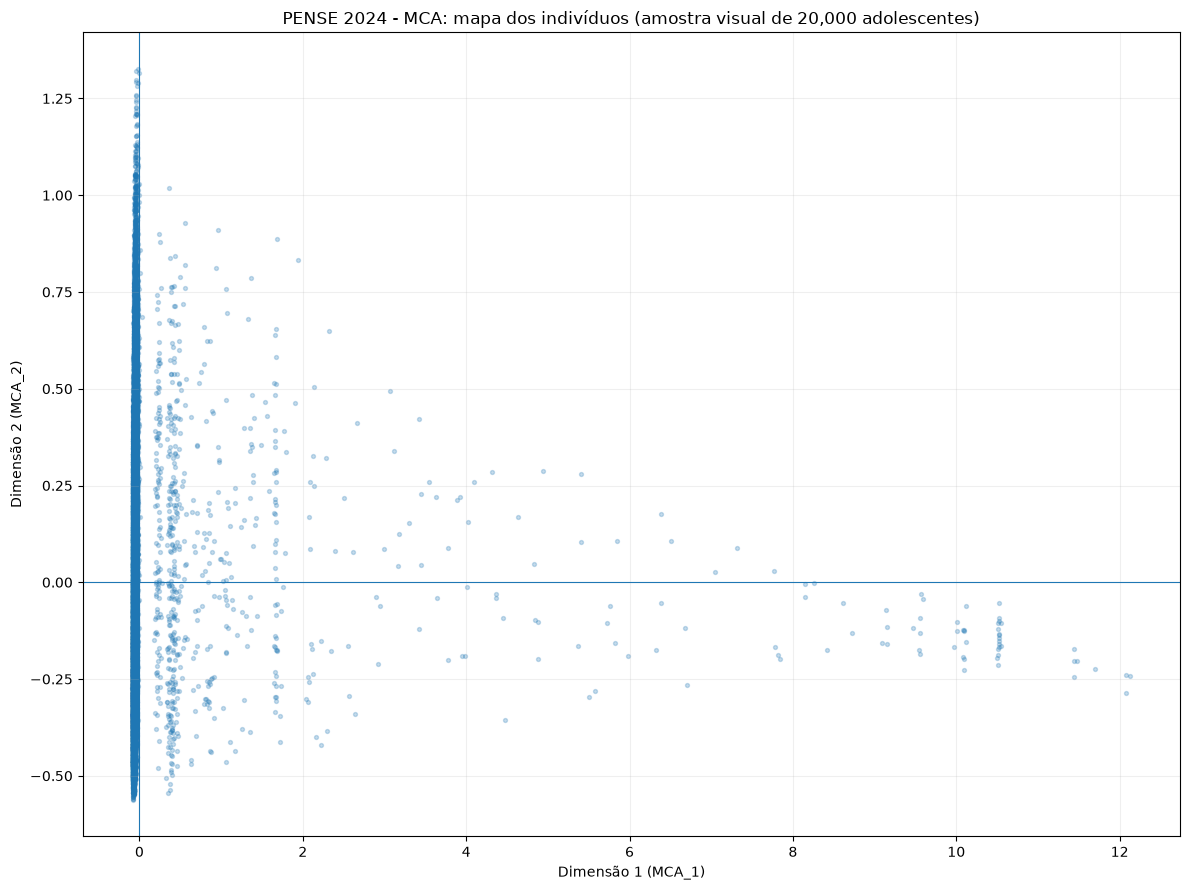


========== RECOMENDAÇÃO PARA K-MEANS ==========
Dimensões com inércia corrigida positiva: 22
Meta de inércia corrigida: 70.0 %
Número inicial recomendado: 2
Inércia corrigida acumulada nessa solução: 93.3 %

Teste também soluções com: [2, 3, 5, 8]

IMPORTANTE: valide a escolha final comparando estabilidade dos clusters, silhouette, Davies-Bouldin, Calinski-Harabasz e interpretabilidade substantiva dos grupos.

========== RESUMO FINAL ==========
Registros analisados: 118036
Variáveis categóricas ativas: 39
Categorias analisadas: 128
Dimensões calculadas: 30
Dimensões recomendadas inicialmente: 2
Arquivo de coordenadas salvo em:
/Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/02_Tratamento_dados_database_PENSE_2024/02_Scripts_tratamento_dados_PENSE_2024/08_PENSE2024_MCA_COORDENADAS.feather


In [1]:
# ============================================================
# PENSE 2024 - MCA: REDUÇÃO DE DIMENSIONALIDADE E DIAGNÓSTICOS
#
# Etapas:
# 1. Autovalores e inércia bruta/corrigida de Benzécri
# 2. Scree Plot
# 3. Inércia acumulada
# 4. Contribuição das categorias
# 5. Cos² das categorias
# 6. Coordenadas das categorias
# 7. Mapa perceptual das categorias (Dimensão 1 x 2)
# 8. Mapa dos indivíduos (Dimensão 1 x 2)
# 9. Recomendação inicial de dimensões para K-means
#
# Saída em arquivo:
# 08_PENSE2024_MCA_COORDENADAS.feather
#
# As tabelas e os gráficos são exibidos no notebook/VS Code.
# ============================================================

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import prince

# ------------------------------------------------------------
# 1. CONFIGURAÇÕES
# ------------------------------------------------------------

arquivo = Path(
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024/"
    "07_PENSE2024_IDADE_13_A_17_CATEGORY.feather"
)

arquivo_coordenadas = (
    arquivo.parent / "08_PENSE2024_MCA_COORDENADAS.feather"
)

N_DIMENSOES_MAX = 30
N_ITER = 10
RANDOM_STATE = 42

# Número máximo de indivíduos exibidos no mapa (apenas visualização).
# O MCA e o arquivo Feather continuam contendo todos os indivíduos.
MAX_INDIVIDUOS_GRAFICO = 20000

# Número máximo de categorias identificadas no mapa perceptual.
MAX_CATEGORIAS_MAPA = 40

# Meta utilizada apenas como orientação inicial para recomendar
# o número de dimensões com base na inércia corrigida.
META_INERCIA_CORRIGIDA = 70.0

# ------------------------------------------------------------
# 2. CARREGAR E PREPARAR A BASE
# ------------------------------------------------------------

if not arquivo.exists():
    raise FileNotFoundError(
        f"Arquivo de entrada não encontrado:\n{arquivo}\n"
        "Verifique o caminho na seção 1."
    )

df = pd.read_feather(arquivo)

print("Dimensões originais:", df.shape)
print("\nTipos de dados:")
print(df.dtypes.value_counts())

indice_original = df.index.copy()

X = df.copy()

# Converter todas as variáveis para strings Python convencionais.
# Evita possíveis incompatibilidades entre pandas StringDtype,
# Prince e operações com matrizes esparsas do SciPy.
for coluna in X.columns:
    X[coluna] = X[coluna].astype(object).map(
        lambda valor: valor.strip() if isinstance(valor, str) else valor
    )

# Transformar strings vazias em valores ausentes.
X = X.replace(r"^\s*$", pd.NA, regex=True)

print("\nPercentual de valores ausentes por variável:")
print(
    (X.isna().mean() * 100)
    .round(2)
    .sort_values(ascending=False)
    .to_string()
)

# Tratar ausência como categoria explícita e garantir dtype object.
X = X.fillna("Não informado").astype(object)

# Verificação dos tipos: todas as colunas devem ser object.
print("\nTipos de dados preparados para o MCA:")
print(X.dtypes.value_counts())

# Remover variáveis constantes.
variaveis_constantes = [
    coluna for coluna in X.columns
    if X[coluna].nunique(dropna=False) <= 1
]

print("\nVariáveis constantes removidas:")
print(variaveis_constantes)

X = X.drop(columns=variaveis_constantes)

# IMPORTANTE:
# Remova identificadores e variáveis administrativas antes do MCA.
# Exemplo:
# colunas_excluir = ["ID_ALUNO", "CODIGO_ESCOLA"]
# X = X.drop(columns=colunas_excluir, errors="ignore")

if X.shape[1] < 2:
    raise ValueError(
        "O MCA precisa de pelo menos duas variáveis categóricas "
        "não constantes."
    )

n_variaveis = X.shape[1]
n_dimensoes = min(N_DIMENSOES_MAX, n_variaveis)

print("\nDimensões após preparação:", X.shape)
print("Número de variáveis ativas no MCA:", n_variaveis)
print("Número máximo de dimensões solicitadas:", n_dimensoes)

# ------------------------------------------------------------
# 3. EXECUTAR O MCA
# ------------------------------------------------------------

mca = prince.MCA(
    n_components=n_dimensoes,
    n_iter=N_ITER,
    random_state=RANDOM_STATE
)

mca = mca.fit(X)

# Usar métodos públicos do Prince.
# Se a instalação do SciPy/Prince ainda apresentar incompatibilidade
# na multiplicação de matrizes esparsas, exibir os tipos internos.
try:
    coordenadas_individuos = mca.row_coordinates(X)
    coordenadas_categorias = mca.column_coordinates(X)
except ValueError as erro:
    print("\\nErro ao calcular coordenadas do MCA.")
    print("Versões instaladas:")
    import scipy
    import sklearn
    print("pandas:", pd.__version__)
    print("numpy:", np.__version__)
    print("scipy:", scipy.__version__)
    print("scikit-learn:", sklearn.__version__)
    print("prince:", getattr(prince, "__version__", "versão não exposta"))
    print("\\nTipo de X:", X.dtypes.value_counts().to_dict())
    if hasattr(mca, "col_masses_"):
        print("dtype col_masses_:", getattr(mca.col_masses_, "dtype", "não disponível"))
    if hasattr(mca, "svd_") and hasattr(mca.svd_, "V"):
        print("dtype SVD V:", getattr(mca.svd_.V, "dtype", "não disponível"))
    raise RuntimeError(
        "A conversão para object não resolveu a incompatibilidade. "
        "Envie as versões e os dtypes impressos acima para ajustar "
        "a combinação Prince/SciPy."
    ) from erro

# Preservar a identificação/ordem original dos adolescentes.
coordenadas_individuos.index = indice_original

# Padronizar nomes das dimensões.
n_dim_real = coordenadas_individuos.shape[1]
nomes_dimensoes = [f"MCA_{i+1}" for i in range(n_dim_real)]

coordenadas_individuos.columns = nomes_dimensoes
coordenadas_categorias.columns = nomes_dimensoes

print("\nMCA concluído.")
print("Coordenadas dos indivíduos:", coordenadas_individuos.shape)
print("Coordenadas das categorias:", coordenadas_categorias.shape)

# ------------------------------------------------------------
# 4. AUTOVALORES E INÉRCIA BRUTA / CORRIGIDA DE BENZÉCRI
# ------------------------------------------------------------

autovalores = np.asarray(mca.eigenvalues_, dtype=float)
autovalores = autovalores[:n_dim_real]

# Inércia bruta relativa às dimensões extraídas.
soma_inercia_bruta = autovalores.sum()

if soma_inercia_bruta > 0:
    inercia_bruta_pct = autovalores / soma_inercia_bruta * 100
else:
    inercia_bruta_pct = np.zeros_like(autovalores)

inercia_bruta_acum_pct = np.cumsum(inercia_bruta_pct)

# Correção de Benzécri:
# lambda_corr = [Q / (Q - 1)]² * (lambda - 1/Q)²
# somente para lambda > 1/Q; nos demais casos, zero.
#
# Q = número de variáveis ativas no MCA.
# A correção é aplicada aos autovalores do MCA convencional.
Q = n_variaveis
limiar_benzecri = 1.0 / Q

autovalores_corrigidos = np.where(
    autovalores > limiar_benzecri,
    (Q / (Q - 1)) ** 2 * (autovalores - limiar_benzecri) ** 2,
    0.0
)

soma_corrigida = autovalores_corrigidos.sum()

if soma_corrigida > 0:
    inercia_corrigida_pct = (
        autovalores_corrigidos / soma_corrigida * 100
    )
else:
    inercia_corrigida_pct = np.zeros_like(autovalores_corrigidos)

inercia_corrigida_acum_pct = np.cumsum(inercia_corrigida_pct)

tabela_inercia = pd.DataFrame({
    "Dimensao": nomes_dimensoes,
    "Autovalor_bruto": autovalores,
    "Inercia_bruta_pct_dimensoes_extraidas": inercia_bruta_pct,
    "Inercia_bruta_acumulada_pct": inercia_bruta_acum_pct,
    "Autovalor_corrigido_Benzecri": autovalores_corrigidos,
    "Inercia_corrigida_Benzecri_pct": inercia_corrigida_pct,
    "Inercia_corrigida_acumulada_pct": inercia_corrigida_acum_pct
})

print("\n========== AUTOVALORES E INÉRCIA ==========")
print(tabela_inercia.round(4).to_string(index=False))
print("\nNúmero de variáveis ativas (Q):", Q)
print("Limiar de Benzécri (1/Q):", round(limiar_benzecri, 6))
print(
    "Dimensões com autovalor acima do limiar:",
    int((autovalores > limiar_benzecri).sum())
)

if soma_corrigida <= 0:
    warnings.warn(
        "Nenhum autovalor ficou acima do limiar de Benzécri. "
        "A inércia corrigida não permite recomendar dimensões. "
        "Confira a parametrização e os dados."
    )

# ------------------------------------------------------------
# 5. GRÁFICO SCREE PLOT
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))
plt.plot(
    range(1, len(autovalores) + 1),
    autovalores,
    marker="o",
    label="Autovalor bruto"
)
plt.plot(
    range(1, len(autovalores_corrigidos) + 1),
    autovalores_corrigidos,
    marker="s",
    label="Autovalor corrigido (Benzécri)"
)
plt.xlabel("Dimensão")
plt.ylabel("Autovalor")
plt.title("PENSE 2024 - MCA: Scree Plot")
plt.xticks(range(1, len(autovalores) + 1))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. GRÁFICO DE INÉRCIA ACUMULADA
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))
plt.plot(
    range(1, len(autovalores) + 1),
    inercia_bruta_acum_pct,
    marker="o",
    label="Inércia bruta acumulada"
)
plt.plot(
    range(1, len(autovalores_corrigidos) + 1),
    inercia_corrigida_acum_pct,
    marker="s",
    label="Inércia corrigida acumulada (Benzécri)"
)
plt.axhline(
    META_INERCIA_CORRIGIDA,
    linestyle="--",
    label=f"Meta orientativa: {META_INERCIA_CORRIGIDA:.0f}%"
)
plt.xlabel("Número de dimensões")
plt.ylabel("Inércia acumulada (%)")
plt.title("PENSE 2024 - MCA: inércia acumulada")
plt.xticks(range(1, len(autovalores) + 1))
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. CONTRIBUIÇÃO DAS CATEGORIAS
# ------------------------------------------------------------

# Algumas versões do Prince não implementam column_contributions().
# Calculamos a contribuição pela definição da Análise de Correspondência:
#
# Contribuição da categoria j na dimensão k =
# massa_j * coordenada_jk² / autovalor_k * 100
#
# As coordenadas são obtidas pelo método público column_coordinates().
# As massas das categorias são obtidas do atributo col_masses_ do Prince.

coords_cat_num = coordenadas_categorias.astype(float).copy()

massas_obj = mca.col_masses_

if isinstance(massas_obj, pd.Series):
    massas_categorias = massas_obj.reindex(coords_cat_num.index)
else:
    massas_array = np.asarray(massas_obj).reshape(-1)
    if len(massas_array) != len(coords_cat_num):
        raise ValueError(
            "Não foi possível alinhar as massas das categorias "
            "às coordenadas retornadas pelo Prince."
        )
    massas_categorias = pd.Series(
        massas_array,
        index=coords_cat_num.index
    )

if massas_categorias.isna().any():
    raise ValueError(
        "Há massas de categorias sem correspondência com as coordenadas. "
        "Confira o índice de mca.col_masses_ e de coordenadas_categorias."
    )

massas_categorias = massas_categorias.astype(float)

contribuicoes = pd.DataFrame(
    index=coords_cat_num.index,
    columns=nomes_dimensoes,
    dtype=float
)

for i, dimensao in enumerate(nomes_dimensoes):
    if autovalores[i] > 0:
        contribuicoes[dimensao] = (
            massas_categorias * coords_cat_num[dimensao].pow(2)
            / autovalores[i] * 100
        )
    else:
        contribuicoes[dimensao] = 0.0

contribuicoes_pct = contribuicoes.copy()

# Em uma solução CA/MCA corretamente escalada, a soma das
# contribuições de cada dimensão deve ficar próxima de 100%.
# Não normalizamos novamente: preservamos a definição matemática.
print("\n========== CONTRIBUIÇÃO DAS CATEGORIAS ==========")
print("Soma das contribuições por dimensão (%):")
print(contribuicoes.sum(axis=0).round(4).to_string())

for dimensao in nomes_dimensoes:
    print(f"\n{dimensao} - 20 categorias com maior contribuição")
    print(
        contribuicoes[dimensao]
        .sort_values(ascending=False)
        .head(20)
        .round(3)
        .to_string()
    )

# ------------------------------------------------------------
# 8. COS² DAS CATEGORIAS
# ------------------------------------------------------------

# Cos² de uma categoria em uma dimensão:
# coordenada_jk² / distância² da categoria à origem.
#
# A distância é calculada usando todas as dimensões disponíveis
# no resultado do MCA. Se somente 20 dimensões foram extraídas,
# o Cos² representa a qualidade de representação relativamente
# ao espaço extraído, não necessariamente ao espaço completo.

distancia2_categorias = coords_cat_num.pow(2).sum(axis=1)

cos2_categorias = coords_cat_num.pow(2).div(
    distancia2_categorias.replace(0, np.nan),
    axis=0
).fillna(0.0)

print("\n========== COS² DAS CATEGORIAS ==========")

for dimensao in nomes_dimensoes:
    print(f"\n{dimensao} - 20 categorias com maior Cos²")
    print(
        cos2_categorias[dimensao]
        .sort_values(ascending=False)
        .head(20)
        .round(4)
        .to_string()
    )

# ------------------------------------------------------------
# 9. TABELA CONSOLIDADA DAS CATEGORIAS
# ------------------------------------------------------------

# O índice do Prince normalmente identifica variável/categoria.
# Transformar o índice em texto para facilitar exportação/consulta.
def nome_categoria(indice):
    if isinstance(indice, tuple):
        return " | ".join(map(str, indice))
    return str(indice)

tabela_categorias = pd.DataFrame(index=coordenadas_categorias.index)
tabela_categorias["Categoria"] = [
    nome_categoria(idx) for idx in tabela_categorias.index
]

for dimensao in nomes_dimensoes:
    tabela_categorias[f"Coordenada_{dimensao}"] = (
        coordenadas_categorias[dimensao]
    )
    tabela_categorias[f"Contribuicao_{dimensao}_pct"] = (
        contribuicoes_pct[dimensao]
    )
    tabela_categorias[f"Cos2_{dimensao}"] = (
        cos2_categorias[dimensao]
    )

print("\n========== TABELA CONSOLIDADA DAS CATEGORIAS ==========")
print(
    tabela_categorias
    .sort_values("Contribuicao_MCA_1_pct", ascending=False)
    .head(30)
    .round(4)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 10. MAPA PERCEPTUAL DAS CATEGORIAS - MCA 1 x MCA 2
# ------------------------------------------------------------

if n_dim_real < 2:
    warnings.warn(
        "O MCA retornou menos de duas dimensões. "
        "Não será possível produzir os mapas 1 x 2."
    )
else:
    # Selecionar categorias mais relevantes para evitar excesso
    # de rótulos. O critério é a soma das contribuições nas
    # duas primeiras dimensões.
    relevancia_12 = (
        contribuicoes_pct["MCA_1"] +
        contribuicoes_pct["MCA_2"]
    )

    indices_top = relevancia_12.nlargest(
        min(MAX_CATEGORIAS_MAPA, len(relevancia_12))
    ).index

    mapa_cat = coordenadas_categorias.loc[indices_top].copy()

    plt.figure(figsize=(15, 11))
    plt.axhline(0, linewidth=0.8)
    plt.axvline(0, linewidth=0.8)

    plt.scatter(
        coordenadas_categorias["MCA_1"],
        coordenadas_categorias["MCA_2"],
        alpha=0.25,
        s=20,
        label="Demais categorias"
    )

    plt.scatter(
        mapa_cat["MCA_1"],
        mapa_cat["MCA_2"],
        alpha=0.85,
        s=35,
        label="Categorias com maior contribuição"
    )

    for idx, linha in mapa_cat.iterrows():
        plt.annotate(
            nome_categoria(idx),
            (linha["MCA_1"], linha["MCA_2"]),
            fontsize=8,
            alpha=0.85
        )

    plt.xlabel("Dimensão 1 (MCA_1)")
    plt.ylabel("Dimensão 2 (MCA_2)")
    plt.title(
        "PENSE 2024 - MCA: mapa perceptual das categorias "
        "(categorias mais contributivas destacadas)"
    )
    plt.grid(alpha=0.2)
    plt.legend()
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 11. MAPA DOS INDIVÍDUOS - MCA 1 x MCA 2
# ------------------------------------------------------------

if n_dim_real >= 2:
    n_plot = min(MAX_INDIVIDUOS_GRAFICO, len(coordenadas_individuos))

    amostra = coordenadas_individuos.sample(
        n=n_plot,
        random_state=RANDOM_STATE
    )

    plt.figure(figsize=(12, 9))
    plt.scatter(
        amostra["MCA_1"],
        amostra["MCA_2"],
        alpha=0.25,
        s=8
    )
    plt.axhline(0, linewidth=0.8)
    plt.axvline(0, linewidth=0.8)
    plt.xlabel("Dimensão 1 (MCA_1)")
    plt.ylabel("Dimensão 2 (MCA_2)")
    plt.title(
        f"PENSE 2024 - MCA: mapa dos indivíduos "
        f"(amostra visual de {n_plot:,} adolescentes)"
    )
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 12. RECOMENDAÇÃO INICIAL DO NÚMERO DE DIMENSÕES PARA K-MEANS
# ------------------------------------------------------------

# Critério principal: menor número de dimensões que alcança
# a meta definida de inércia corrigida de Benzécri.
# A recomendação é exploratória, não uma decisão automática.
dimensoes_positivas = int((autovalores_corrigidos > 0).sum())

if soma_corrigida > 0 and dimensoes_positivas > 0:
    acumulada_positiva = inercia_corrigida_acum_pct[
        :dimensoes_positivas
    ]

    candidatos = np.where(
        acumulada_positiva >= META_INERCIA_CORRIGIDA
    )[0]

    if len(candidatos) > 0:
        n_recomendado = int(candidatos[0] + 1)
    else:
        n_recomendado = dimensoes_positivas

    # Para clusterização, duas dimensões no mínimo facilitam
    # análise e visualização, desde que existam duas dimensões úteis.
    if dimensoes_positivas >= 2:
        n_recomendado = max(2, n_recomendado)
    else:
        n_recomendado = dimensoes_positivas

    print("\n========== RECOMENDAÇÃO PARA K-MEANS ==========")
    print("Dimensões com inércia corrigida positiva:", dimensoes_positivas)
    print("Meta de inércia corrigida:", META_INERCIA_CORRIGIDA, "%")
    print("Número inicial recomendado:", n_recomendado)
    print(
        "Inércia corrigida acumulada nessa solução:",
        round(inercia_corrigida_acum_pct[n_recomendado - 1], 2),
        "%"
    )
    print(
        "\nTeste também soluções com:",
        sorted(set([
            max(2, min(3, dimensoes_positivas)),
            max(2, min(5, dimensoes_positivas)),
            max(2, min(8, dimensoes_positivas)),
            n_recomendado
        ]))
    )
else:
    n_recomendado = None
    print(
        "\nNão foi possível recomendar o número de dimensões "
        "pela inércia corrigida de Benzécri."
    )

print(
    "\nIMPORTANTE: valide a escolha final comparando estabilidade "
    "dos clusters, silhouette, Davies-Bouldin, Calinski-Harabasz "
    "e interpretabilidade substantiva dos grupos."
)

# ------------------------------------------------------------
# 13. SALVAR COORDENADAS DOS INDIVÍDUOS PARA K-MEANS
# ------------------------------------------------------------

saida = coordenadas_individuos.copy()
saida.index.name = "indice_original"
saida = saida.reset_index()

saida.to_feather(arquivo_coordenadas)

print("\n========== RESUMO FINAL ==========")
print("Registros analisados:", X.shape[0])
print("Variáveis categóricas ativas:", X.shape[1])
print("Categorias analisadas:", coordenadas_categorias.shape[0])
print("Dimensões calculadas:", n_dim_real)
print("Dimensões recomendadas inicialmente:", n_recomendado)
print("Arquivo de coordenadas salvo em:")
print(arquivo_coordenadas)
print("=================================")


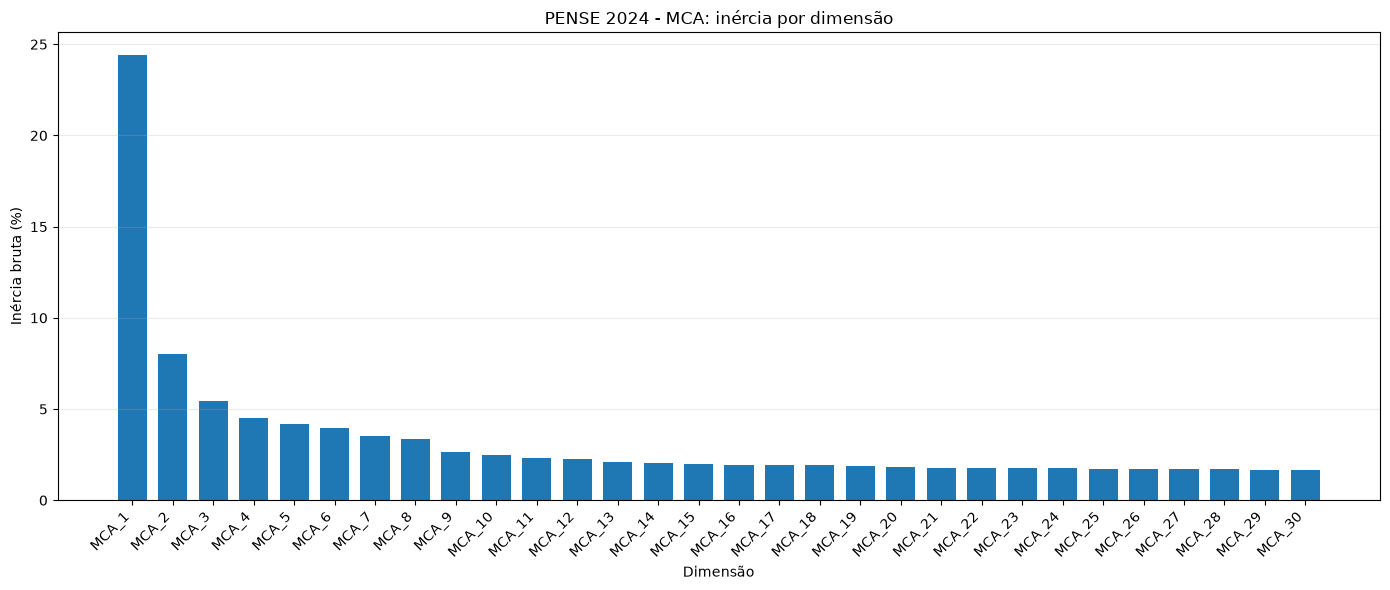

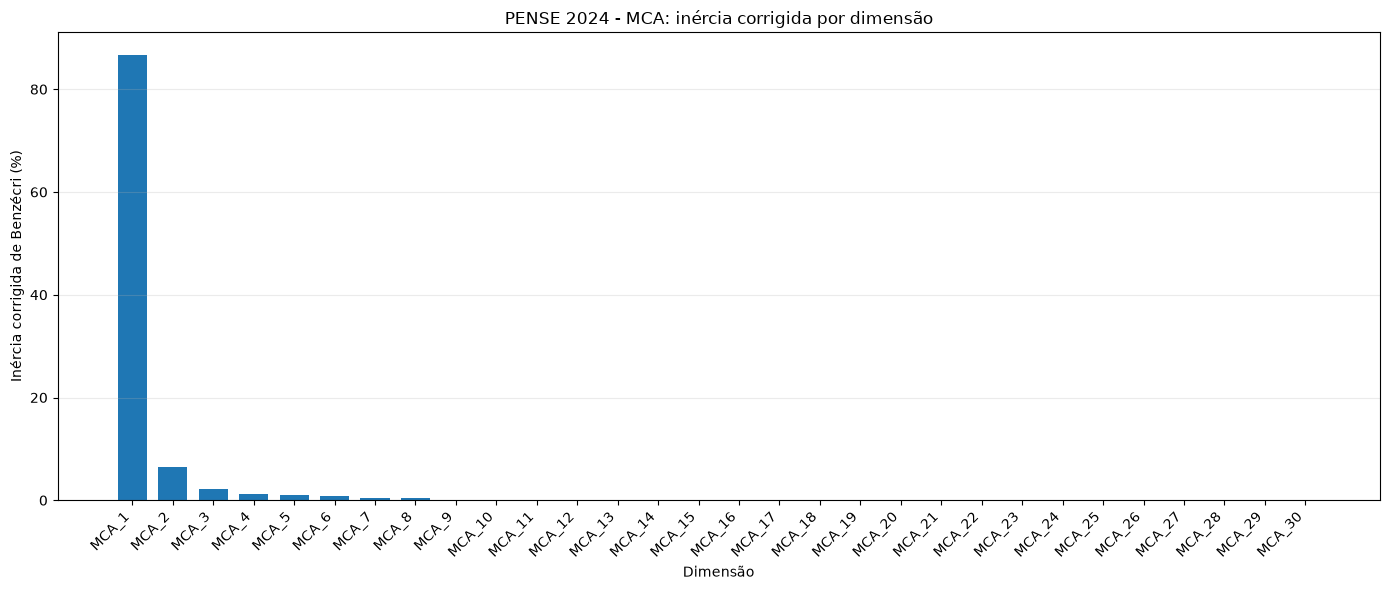

In [2]:
# ------------------------------------------------------------
# 5B. GRÁFICO DE INÉRCIA POR DIMENSÃO (PERCENTUAL)
# ------------------------------------------------------------

# Percentuais calculados em relação à soma dos autovalores
# extraídos pelo MCA (até N_DIMENSOES_MAX dimensões).
# Portanto, não representam necessariamente a inércia do espaço
# completo caso existam dimensões além das extraídas.
posicoes = np.arange(1, len(inercia_bruta_pct) + 1)

plt.figure(figsize=(14, 6))
plt.bar(posicoes, inercia_bruta_pct, width=0.72)
plt.xlabel("Dimensão")
plt.ylabel("Inércia bruta (%)")
plt.title("PENSE 2024 - MCA: inércia por dimensão")
plt.xticks(posicoes, [f"MCA_{i}" for i in posicoes], rotation=45, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Gráfico complementar: percentual corrigido por dimensão.
plt.figure(figsize=(14, 6))
plt.bar(posicoes, inercia_corrigida_pct, width=0.72)
plt.xlabel("Dimensão")
plt.ylabel("Inércia corrigida de Benzécri (%)")
plt.title("PENSE 2024 - MCA: inércia corrigida por dimensão")
plt.xticks(posicoes, [f"MCA_{i}" for i in posicoes], rotation=45, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


In [3]:
import pandas as pd

arquivo = "08_PENSE2024_MCA_COORDENADAS.feather"

df = pd.read_feather(arquivo)

dimensoes = [col for col in df.columns if col.startswith("MCA_")]

print("Número de registros:", len(df))
print("Número de dimensões:", len(dimensoes))
print("Dimensões disponíveis:", dimensoes)

Número de registros: 118036
Número de dimensões: 30
Dimensões disponíveis: ['MCA_1', 'MCA_2', 'MCA_3', 'MCA_4', 'MCA_5', 'MCA_6', 'MCA_7', 'MCA_8', 'MCA_9', 'MCA_10', 'MCA_11', 'MCA_12', 'MCA_13', 'MCA_14', 'MCA_15', 'MCA_16', 'MCA_17', 'MCA_18', 'MCA_19', 'MCA_20', 'MCA_21', 'MCA_22', 'MCA_23', 'MCA_24', 'MCA_25', 'MCA_26', 'MCA_27', 'MCA_28', 'MCA_29', 'MCA_30']
